# Imports 

In [1]:
import contextily as ctx
import os
import sys
from datetime import datetime
from glob import glob
import urllib
from pathlib import Path
import cdsapi
import geopandas as gpd
import hvplot.xarray
import imageio
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import hvplot.pandas
import rasterio
import pandas as pd
import xarray as xr
import openeo
from openeo.api.process import Parameter
from shapely.geometry import Point, box
from pyproj import Transformer
import rioxarray 
from datetime import datetime
from pystac_client import Client
import bokeh
from tqdm.notebook import tqdm

# AOI and POI

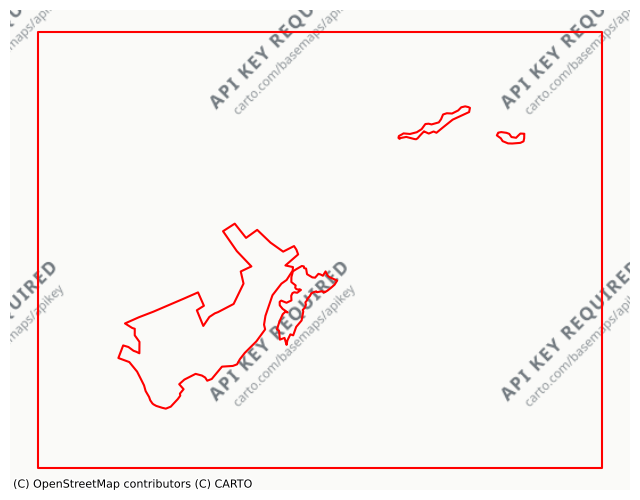

In [2]:
# site_name = 'leze' # ['2022-01-01', '2022-01-31'] 
# site_name = 'pinios'
site_name = 'vecht' # ['2022-06-01', '2022-08-31']

## Period of interest
poi = ['2021-01-01', '2021-12-31']
startYear = int(poi[0][:4])
endYear = int(poi[1][:4])

if site_name == 'pinios':
    aois = gpd.read_file('/Users/vm/Desktop/dir.tmp/spongeworks/data/Pinios/gis_data/s7_lake_karla/s7_lake_karla.shp')
if site_name == 'vecht':
    aois1 = gpd.read_file('/Users/vm/Desktop/dir.tmp/spongeworks/data/Vecht/vecht_top_aos 1.gpkg')
    aois2 = gpd.read_file('/Users/vm/Desktop/dir.tmp/spongeworks/data/Vecht/vecht_top_sites.gpkg')
    aois = gpd.GeoDataFrame(pd.concat([aois1, aois2], ignore_index=True), crs=aois1.crs)
if site_name == 'leze':    
    aoi1 = gpd.read_file('/Users/vm/Desktop/dir.tmp/spongeworks/data/Leze/hedges_aos.gpkg')
    aoi2 = gpd.read_file('/Users/vm/Desktop/dir.tmp/spongeworks/data/Leze/eval_sites_aos.gpkg')
    aois = gpd.GeoDataFrame(pd.concat([aoi1, aoi2], ignore_index=True), crs=aoi1.crs)
    # aois = gpd.read_file('/Users/vm/Desktop/dir.tmp/spongeworks/data/Leze/eval_sites_aos.gpkg')

aois_web = aois.to_crs(epsg=3857)
ax = aois_web.plot(figsize=(8, 8), facecolor="none", edgecolor="red", linewidth=1.5)
ctx.add_basemap(ax, source=ctx.providers.CartoDB.Positron)
ax.set_axis_off()
plt.show()

# Build bbox from AOIs extent with +2 km margin on each side
aois_metric = aois.to_crs(aois.estimate_utm_crs())
minx, miny, maxx, maxy = aois_metric.total_bounds

bbox_radius = 100  # 100 meters margin

bbox_metric = box(minx - bbox_radius, miny - bbox_radius, maxx + bbox_radius, maxy + bbox_radius)
bbox_gdf = gpd.GeoDataFrame(geometry=[bbox_metric], crs=aois_metric.crs).to_crs("4326")
bbox = bbox_gdf.geometry.iloc[0]


# openeo connection

In [3]:
## Connect to the openEO back-end and authenticate
connection = openeo.connect("openeofed.dataspace.copernicus.eu")
connection.authenticate_oidc()

## Set geographical limits of the bounding box
W = bbox_gdf.total_bounds[0]
S = bbox_gdf.total_bounds[1]
E = bbox_gdf.total_bounds[2]
N = bbox_gdf.total_bounds[3]

Authenticated using refresh token.


In [4]:
# # Build a packaged NDWI UDF and run it as a batch job (CDSE openEO)
# from pathlib import Path
# from glob import glob

# # 1) Store UDF source in a package-like folder for versioning/reuse.
# udf_dir = Path("/Users/vm/Desktop/dir.tmp/spongeworks/src/my_openeo_tools/udfs")
# udf_dir.mkdir(parents=True, exist_ok=True)
# udf_file = udf_dir / "ndwi.py"

# udf_file.write_text(
#     """from openeo.udf import XarrayDataCube
# import numpy as np
# import xarray as xr


# def apply_datacube(cube: XarrayDataCube, context: dict) -> XarrayDataCube:
#     arr = cube.get_array()

#     # Support backends using either 'bands' or 'band'.
#     band_dim = "bands" if "bands" in arr.dims else ("band" if "band" in arr.dims else None)
#     if band_dim is None:
#         raise ValueError(f"No band dimension found. Available dims: {arr.dims}")

#     b03 = arr.sel({band_dim: "B03"}) * 0.0001
#     b08 = arr.sel({band_dim: "B08"}) * 0.0001
#     scl = arr.sel({band_dim: "SCL"})

#     # Mask cloud/shadow classes: 3 (shadow), 8/9 (cloud)
#     clear_mask = ~scl.isin([3, 8, 9])
#     ndwi = xr.where(clear_mask, (b03 - b08) / (b03 + b08), np.nan)

#     # Return one-band cube named NDWI.
#     ndwi = ndwi.expand_dims({band_dim: ["NDWI"]})
#     return XarrayDataCube(ndwi)
# """,
#     encoding="utf-8",
# )

# print(f"UDF source written to: {udf_file}")

# # 2) Load UDF from file and orchestrate execution client-side.
# udf = openeo.UDF.from_file(udf_file)
# output_dir = f"/Users/vm/Desktop/dir.tmp/spongeworks/eo_data/{site_name}/ndwi_udf/"
# os.makedirs(output_dir, exist_ok=True)

# # Set to True only when you explicitly want to block until all jobs finish.
# wait_for_completion = False


# def ensure_ndwi_datavar(nc_file: str) -> None:
#     """Guarantee NDWI is exposed as a data_var in the downloaded NetCDF."""
#     with xr.open_dataset(nc_file, engine="netcdf4") as ds:
#         ds_local = ds.load()

#     if "ndwi" in ds_local.data_vars:
#         final_ds = ds_local
#     elif "NDWI" in ds_local.data_vars:
#         final_ds = ds_local.rename({"NDWI": "ndwi"})
#     elif {"B03", "B08"}.issubset(set(ds_local.data_vars)):
#         b03 = ds_local["B03"] * 0.0001
#         b08 = ds_local["B08"] * 0.0001
#         ndwi = (b03 - b08) / (b03 + b08)
#         if "SCL" in ds_local.data_vars:
#             ndwi = ndwi.where(~ds_local["SCL"].isin([3, 8, 9]))
#         final_ds = xr.Dataset({"ndwi": ndwi})
#     else:
#         # Handle band-stacked outputs where NDWI is a band coordinate, not a data_var.
#         first_var = next((v for v in ds_local.data_vars if v != "crs"), None)
#         if first_var is None:
#             raise ValueError(f"No usable variable found in {nc_file}")
#         da = ds_local[first_var]
#         band_dim = "bands" if "bands" in da.dims else ("band" if "band" in da.dims else None)
#         if band_dim is not None:
#             labels = [str(x) for x in da.coords[band_dim].values]
#             if "NDWI" in labels:
#                 da = da.sel({band_dim: "NDWI"})
#             elif "ndwi" in labels:
#                 da = da.sel({band_dim: "ndwi"})
#             else:
#                 da = da.isel({band_dim: 0})
#         final_ds = xr.Dataset({"ndwi": da})

#     if "crs" in ds_local.variables and "crs" not in final_ds.variables:
#         final_ds["crs"] = ds_local["crs"]
#     final_ds.attrs.update(ds_local.attrs)

#     tmp = nc_file + ".tmp"
#     final_ds.to_netcdf(tmp, engine="netcdf4")
#     os.replace(tmp, nc_file)


# # 3) Year-by-year batch execution for resilience.
# submitted_jobs = []
# for year in range(startYear, endYear + 1):
#     year_start = max(f"{year}-01-01", poi[0])
#     year_end = min(f"{year}-12-31", poi[1])
#     if year_start > year_end:
#         continue

#     year_dir = os.path.join(output_dir, str(year))
#     os.makedirs(year_dir, exist_ok=True)

#     out_nc = os.path.join(year_dir, f"{site_name}_ndwi_udf_{year}.nc")

#     cube = connection.load_collection(
#         "SENTINEL2_L2A",
#         spatial_extent={"west": W, "south": S, "east": E, "north": N, "crs": "EPSG:4326"},
#         temporal_extent=[year_start, year_end],
#         bands=["B03", "B08", "SCL"],
#         max_cloud_cover=50,
#     )

#     result_cube = cube.apply(process=udf, context={})

#     job = result_cube.create_job(
#         title=f"S2_NDWI_UDF_{site_name}_{year}",
#         out_format="NetCDF",
#     )
#     submitted_jobs.append((year, year_dir, out_nc, job))
#     print(f"Submitted year {year}: job_id={job.job_id}")

#     if wait_for_completion:
#         job.start_and_wait()
#         job.get_results().download_files(year_dir)

#         # Pick newest NC from the year folder and normalize it to contain `ndwi`.
#         nc_candidates = sorted(glob(os.path.join(year_dir, "*.nc")), key=os.path.getmtime)
#         if not nc_candidates:
#             raise FileNotFoundError(f"No NetCDF downloaded for year {year} in {year_dir}")

#         newest_nc = nc_candidates[-1]
#         if newest_nc != out_nc:
#             os.replace(newest_nc, out_nc)

#         ensure_ndwi_datavar(out_nc)

#         with xr.open_dataset(out_nc, engine="netcdf4") as check_ds:
#             print(f"{year}: {out_nc} data_vars={list(check_ds.data_vars)}")

# if not wait_for_completion:
#     print("Jobs submitted. To finish/download, set wait_for_completion=True and rerun this cell.")

In [5]:
# # Optional step: start submitted jobs, wait for completion, download NetCDF, and normalize NDWI variable
# from glob import glob

# if "submitted_jobs" not in globals() or not submitted_jobs:
#     print("No submitted jobs found. Run Cell 4 first.")
# else:
#     for year, year_dir, out_nc, job in submitted_jobs:
#         print(f"Starting job for {year}: {job.job_id}")
#         job.start_and_wait()
#         job.get_results().download_files(year_dir)

#         nc_candidates = sorted(glob(os.path.join(year_dir, "*.nc")), key=os.path.getmtime)
#         if not nc_candidates:
#             raise FileNotFoundError(f"No NetCDF downloaded for year {year} in {year_dir}")

#         newest_nc = nc_candidates[-1]
#         if newest_nc != out_nc:
#             os.replace(newest_nc, out_nc)

#         ensure_ndwi_datavar(out_nc)

#         with xr.open_dataset(out_nc, engine="netcdf4") as check_ds:
#             print(f"{year}: {out_nc} data_vars={list(check_ds.data_vars)}")

# NWDI UPD 

In [ ]:
# CDSE openEO: reusable Sentinel-2 NDWI UDP
#
# Assumes these variables already exist:
#   connection : authenticated openeo.Connection
#   site_name  : str
#   poi        : ["YYYY-MM-DD", "YYYY-MM-DD"]
#   W, S, E, N : bbox in EPSG:4326
#   startYear, endYear : integers
#
# Important:
# - No np.nan appears anywhere in this script.
# - `replacement=None` becomes valid JSON null, i.e. no-data.
# - The mask is True for cloud/shadow pixels that should be removed.


import json
import math
import os
from glob import glob

import xarray as xr
from openeo.api.process import Parameter


# =========================================================================
# Settings
# =========================================================================

UDP_ID = "ndwi_s2_clear_v2"
MAX_CLOUD_COVER = 50
wait_for_completion = False

output_dir = os.path.join(
    "/Users/vm/Desktop/dir.tmp/spongeworks/eo_data",
    site_name,
    "ndwi_udp",
)
os.makedirs(output_dir, exist_ok=True)


# =========================================================================
# Utility: identify non-finite numbers before attempting an API request
# =========================================================================

def find_nonfinite_values(value, location="root"):
    """
    Return the locations of float NaN, +inf, or -inf values in nested data.

    Requests uses strict JSON encoding with allow_nan=False, so any such
    value would cause InvalidJSONError before CDSE receives the request.
    """
    locations = []

    if isinstance(value, float) and not math.isfinite(value):
        locations.append(f"{location} = {value!r}")

    elif isinstance(value, dict):
        for key, item in value.items():
            locations.extend(
                find_nonfinite_values(item, f"{location}.{key}")
            )

    elif isinstance(value, (list, tuple)):
        for index, item in enumerate(value):
            locations.extend(
                find_nonfinite_values(item, f"{location}[{index}]")
            )

    return locations


# =========================================================================
# 1. Define UDP parameters
# =========================================================================

temporal_extent_param = Parameter(
    name="temporal_extent",
    description=(
        "Two-element temporal interval: start date and end date "
        "for the Sentinel-2 L2A query."
    ),
    schema={
        "type": "array",
        "subtype": "temporal-interval",
    },
)

spatial_extent_param = Parameter(
    name="spatial_extent",
    description=(
        "Spatial bounding box in EPSG:4326, supplied as west, south, "
        "east, north, and crs."
    ),
    schema={
        "type": "object",
        "subtype": "geojson",
    },
)

max_cloud_cover_param = Parameter(
    name="max_cloud_cover",
    description=(
        "Maximum Sentinel-2 L2A scene-level cloud-cover percentage."
    ),
    schema={
        "type": "number",
        "minimum": 0,
        "maximum": 100,
    },
)


# =========================================================================
# 2. Build UDP process graph
# =========================================================================

s2_cube = connection.load_collection(
    collection_id="SENTINEL2_L2A",
    spatial_extent=spatial_extent_param,
    temporal_extent=temporal_extent_param,
    bands=["B03", "B08", "SCL"],
    max_cloud_cover=max_cloud_cover_param,
)

# Individual band selection removes the bands dimension.
# The cubes below have dimensions: t, x, y.
b03 = s2_cube.band("B03") * 0.0001
b08 = s2_cube.band("B08") * 0.0001
scl = s2_cube.band("SCL")

# True for SCL classes that should be converted to no-data:
#   3 = cloud shadow
#   8 = cloud, medium probability
#   9 = cloud, high probability
invalid_scl = (scl == 3) | (scl == 8) | (scl == 9)

# NDWI = (Green - NIR) / (Green + NIR)
ndwi = (b03 - b08) / (b03 + b08)

# The default replacement is None (JSON null / openEO no-data).
# Omitting `replacement` entirely removes any risk of a previous NaN
# value entering the graph.
ndwi_masked = ndwi.mask(mask=invalid_scl)

# Re-add a singleton output band axis because `band()` removed the source
# `bands` dimension. This gives the output dimensions t, bands, x, y.
ndwi_udp_graph = ndwi_masked.add_dimension(
    name="bands",
    label="NDWI",
    type="bands",
)


# =========================================================================
# 3. Export and validate graph before saving it to CDSE
# =========================================================================

udp_metadata = {
    "id": UDP_ID,
    "summary": "Sentinel-2 NDWI masked using SCL cloud/shadow classes",
    "description": (
        "Loads Sentinel-2 L2A B03, B08, and SCL. Computes NDWI as "
        "(B03 - B08) / (B03 + B08), after applying scale factor 0.0001 "
        "to reflectance bands. Sets pixels classified in SCL classes 3, "
        "8, or 9 to no-data. Returns one band named NDWI."
    ),
    "parameters": [
        temporal_extent_param.to_dict(),
        spatial_extent_param.to_dict(),
        max_cloud_cover_param.to_dict(),
    ],
    "process_graph": ndwi_udp_graph.flat_graph(),
}

nonfinite_locations = find_nonfinite_values(udp_metadata)

if nonfinite_locations:
    raise ValueError(
        "Non-JSON numeric value(s) found in UDP metadata/process graph:\n"
        + "\n".join(nonfinite_locations)
    )

# This must succeed before attempting the HTTP request. If it does not,
# Python will identify the issue here rather than inside requests.
json.dumps(udp_metadata, allow_nan=False)

print("UDP metadata and process graph are valid strict JSON.")
print("No NaN, +inf, or -inf values found.")


# Optional: write the inspected graph locally for reproducibility/debugging.
udp_debug_json = os.path.join(
    output_dir,
    f"{UDP_ID}_process_graph.json",
)

with open(udp_debug_json, "w", encoding="utf-8") as file:
    json.dump(udp_metadata, file, indent=2, allow_nan=False)

print(f"JSON-safe UDP graph written to: {udp_debug_json}")


# =========================================================================
# 4. Save/update the backend-side UDP
# =========================================================================

connection.save_user_defined_process(
    user_defined_process_id=UDP_ID,
    process_graph=ndwi_udp_graph,
    parameters=[
        temporal_extent_param,
        spatial_extent_param,
        max_cloud_cover_param,
    ],
    summary=udp_metadata["summary"],
    description=udp_metadata["description"],
)

print(f"UDP saved/updated successfully: {UDP_ID}")


# =========================================================================
# 5. Optional utility: standardize downloaded NetCDF variable name
# =========================================================================

def ensure_ndwi_datavar(nc_file: str) -> None:
    """
    Standardize a downloaded NetCDF to a Dataset with data variable `ndwi`.

    Handles either an NDWI data variable directly or a generic raster
    data variable with an NDWI-labelled `bands`/`band` coordinate.
    """
    with xr.open_dataset(nc_file, engine="netcdf4") as ds:
        ds_local = ds.load()

    if "ndwi" in ds_local.data_vars:
        final_ds = ds_local

    elif "NDWI" in ds_local.data_vars:
        final_ds = ds_local.rename({"NDWI": "ndwi"})

    else:
        first_var = next(
            (
                variable
                for variable in ds_local.data_vars
                if variable != "crs"
            ),
            None,
        )

        if first_var is None:
            raise ValueError(
                f"No usable raster variable in NetCDF file: {nc_file}"
            )

        da = ds_local[first_var]

        band_dim = (
            "bands"
            if "bands" in da.dims
            else ("band" if "band" in da.dims else None)
        )

        if band_dim is not None:
            labels = [str(label) for label in da.coords[band_dim].values]

            if "NDWI" in labels:
                da = da.sel({band_dim: "NDWI"})
            elif "ndwi" in labels:
                da = da.sel({band_dim: "ndwi"})
            else:
                raise ValueError(
                    f"No NDWI label found in {band_dim}: {labels}"
                )

        final_ds = xr.Dataset({"ndwi": da})

    if "crs" in ds_local.variables and "crs" not in final_ds.variables:
        final_ds["crs"] = ds_local["crs"]

    final_ds.attrs.update(ds_local.attrs)

    temporary_file = nc_file + ".tmp"
    final_ds.to_netcdf(temporary_file, engine="netcdf4")
    os.replace(temporary_file, nc_file)


# =========================================================================
# 6. Instantiate the stored UDP once per year and execute batch jobs
# =========================================================================

submitted_jobs = []

for year in range(startYear, endYear + 1):
    year_start = max(f"{year}-01-01", poi[0])
    year_end = min(f"{year}-12-31", poi[1])

    if year_start > year_end:
        continue

    year_dir = os.path.join(output_dir, str(year))
    os.makedirs(year_dir, exist_ok=True)

    out_nc = os.path.join(
        year_dir,
        f"{site_name}_ndwi_udp_{year}.nc",
    )

    result_cube = connection.datacube_from_process(
        process_id=UDP_ID,
        temporal_extent=[year_start, year_end],
        spatial_extent={
            "west": W,
            "south": S,
            "east": E,
            "north": N,
            "crs": "EPSG:4326",
        },
        max_cloud_cover=MAX_CLOUD_COVER,
    )

    job = result_cube.create_job(
        title=f"S2_NDWI_UDP_{site_name}_{year}",
        description=(
            f"Cloud/shadow-masked Sentinel-2 NDWI, {site_name}, {year}."
        ),
        out_format="NetCDF",
    )

    submitted_jobs.append(
        {
            "year": year,
            "year_dir": year_dir,
            "out_nc": out_nc,
            "job": job,
        }
    )

    print(f"Created job for {year}: job_id={job.job_id}")

    if wait_for_completion:
        job.start_and_wait()

        job.get_results().download_files(year_dir)

        nc_candidates = sorted(
            glob(os.path.join(year_dir, "*.nc")),
            key=os.path.getmtime,
        )

        if not nc_candidates:
            raise FileNotFoundError(
                f"No NetCDF result downloaded for {year}: {year_dir}"
            )

        latest_nc = nc_candidates[-1]

        if os.path.abspath(latest_nc) != os.path.abspath(out_nc):
            os.replace(latest_nc, out_nc)

        ensure_ndwi_datavar(out_nc)

        with xr.open_dataset(out_nc, engine="netcdf4") as check_ds:
            print(
                f"{year}: completed and normalized\n"
                f"  file: {out_nc}\n"
                f"  variables: {list(check_ds.data_vars)}\n"
                f"  dimensions: {dict(check_ds.sizes)}"
            )

    else:
        job.start_job()
        print(f"Started job for {year}: job_id={job.job_id}")


print(f"\nCreated {len(submitted_jobs)} annual UDP batch job(s).")

if not wait_for_completion:
    print(
        "Jobs are running asynchronously. Set wait_for_completion = True "
        "in a later run if you want the notebook to wait and download."
    )

## Plot results for NDWI 

In [ ]:
import os
from glob import glob
import xarray as xr

year = 2022
year_dir = (
    "/Users/vm/Desktop/dir.tmp/spongeworks/eo_data/"
    "vecht/ndwi_udp/2022"
)
out_nc = os.path.join(year_dir, "vecht_ndwi_udp_2022.nc")

os.makedirs(year_dir, exist_ok=True)

job = connection.job("cdse-j-26090912113743a6a25d7d2595bef699")
job.get_results().download_files(year_dir)

nc_candidates = sorted(
    glob(os.path.join(year_dir, "*.nc")),
    key=os.path.getmtime,
)

if not nc_candidates:
    raise FileNotFoundError(f"No NetCDF asset downloaded to {year_dir}")

latest_nc = nc_candidates[-1]

if os.path.abspath(latest_nc) != os.path.abspath(out_nc):
    os.replace(latest_nc, out_nc)

with xr.open_dataset(out_nc, engine="netcdf4") as ds:
    print(ds)
    print("Data variables:", list(ds.data_vars))

# Flood mask UPD 

## Method

This workflow creates a Sentinel-1 flood-candidate mask from VH backscatter:

1. Loads Sentinel-1 GRD VH data for the selected area and dates.
2. Applies the `sigma0-ellipsoid` backscatter correction using the Copernicus 30 m elevation model.
3. Converts positive VH values to decibels.
4. Classifies pixels below the configurable threshold of **−22.2 dB** as flood candidates (`1`); other valid pixels are classified as non-flood (`0`). Invalid or missing values remain no-data.

This is a simple threshold-based indicator, not a validated flood extent: it includes permanent water and may require threshold tuning and additional masking for a specific site.

For related context, see the [referenced article](https://www.sciencedirect.com/science/article/pii/S0034425726000969?via%3Dihub).

In [ ]:
"""Flood mask UDP based on the working NDWI UDP pattern."""

import json
import os
import xarray as xr
from openeo.api.process import Parameter


UDP_ID = "flood_mask_s1_vh_v2"
VH_WATER_THRESH = -22.2 # VV <−13.4𝑑𝐵 or 𝑉𝐻<−22.2𝑑𝐵
wait_for_completion = False

output_dir = os.path.join(
    "/Users/vm/Desktop/dir.tmp/spongeworks/eo_data",
    site_name,
    "flood_mask_udp",
)
os.makedirs(output_dir, exist_ok=True)

temporal_extent_param = Parameter(
    name="temporal_extent",
    description="Start and end dates for the Sentinel-1 GRD query.",
    schema={"type": "array", "subtype": "temporal-interval"},
)
spatial_extent_param = Parameter(
    name="spatial_extent",
    description="Bounding box in EPSG:4326: west, south, east, north, crs.",
    schema={"type": "object", "subtype": "geojson"},
)
threshold_param = Parameter(
    name="vh_threshold_db",
    description="Flood candidates have VH strictly below this threshold in dB.",
    schema={"type": "number"},
)
udp_parameters = [temporal_extent_param, spatial_extent_param, threshold_param]

s1_cube = connection.load_collection(
    collection_id="SENTINEL1_GRD",
    spatial_extent=spatial_extent_param,
    temporal_extent=temporal_extent_param,
    bands=["VH"],
)
s1_scatter = s1_cube.sar_backscatter(
    coefficient="sigma0-ellipsoid",
    elevation_model="COPERNICUS_30",
)

vh_linear = s1_scatter.band("VH")
# Non-positive values cannot be converted to dB; mask them to no-data.
vh_valid = vh_linear.mask(vh_linear <= 0)
vh_db = 10 * (vh_valid.ln() / 2.302585092994046)

# Boolean comparison gives 1/0 flags; no-data propagates.
flood_mask = vh_db.apply(lambda x: x < threshold_param)

flood_udp_graph = flood_mask.add_dimension(
    name="bands",
    label="flood_mask",
    type="bands",
)

udp_metadata = {
    "id": UDP_ID,
    "summary": "Sentinel-1 VH threshold flood mask",
    "description": (
        "Loads Sentinel-1 GRD VH, computes sigma0-ellipsoid backscatter "
        "(COPERNICUS_30), converts positive VH to dB and returns one "
        "flood_mask band: 1 where VH < vh_threshold_db, otherwise 0. "
        "Non-positive VH is no-data. Includes permanent water."
    ),
    "parameters": [p.to_dict() for p in udp_parameters],
    "process_graph": flood_udp_graph.flat_graph(),
}

json.dumps(udp_metadata, allow_nan=False)
udp_debug_json = os.path.join(output_dir, f"{UDP_ID}_process_graph.json")
with open(udp_debug_json, "w", encoding="utf-8") as file:
    json.dump(udp_metadata, file, indent=2, allow_nan=False)

connection.save_user_defined_process(
    user_defined_process_id=UDP_ID,
    process_graph=flood_udp_graph,
    parameters=udp_parameters,
    summary=udp_metadata["summary"],
    description=udp_metadata["description"],
)
print(f"UDP saved/updated: {UDP_ID}")


def ensure_flood_mask_datavar(nc_file):
    """Normalize the backend's single raster output to variable `flood_mask`."""
    with xr.open_dataset(nc_file, engine="netcdf4") as ds:
        local = ds.load()

    if "flood_mask" in local.data_vars:
        final = local
    else:
        raster_variables = [
            name for name, da in local.data_vars.items() if da.ndim >= 2
        ]
        if len(raster_variables) != 1:
            raise ValueError(
                f"Expected one raster in {nc_file}; found {raster_variables}"
            )
        final = local.rename({raster_variables[0]: "flood_mask"})

    da = final["flood_mask"]
    for band_dim in ("bands", "band"):
        if band_dim in da.dims:
            if da.sizes[band_dim] != 1:
                raise ValueError(f"Expected one output band in {nc_file}.")
            da = da.isel({band_dim: 0}, drop=True)

    da.attrs.update(
        long_name="Sentinel-1 VH threshold flood mask",
        units="1",
        threshold_db=VH_WATER_THRESH,
        description="1 = flood candidate; 0 = non-flood; missing = no-data",
    )
    final["flood_mask"] = da
    temporary_file = nc_file + ".tmp"
    final.to_netcdf(temporary_file, engine="netcdf4")
    os.replace(temporary_file, nc_file)


submitted_flood_jobs = []
for year in range(startYear, endYear + 1):
    if year < 2017:
        continue

    year_start = max(f"{year}-01-01", poi[0])
    year_end = min(f"{year}-12-31", poi[1])
    if year_start > year_end:
        continue

    year_dir = os.path.join(output_dir, str(year))
    os.makedirs(year_dir, exist_ok=True)
    out_nc = os.path.join(year_dir, f"{site_name}_flood_mask_udp_{year}.nc")

    result_cube = connection.datacube_from_process(
        process_id=UDP_ID,
        temporal_extent=[year_start, year_end],
        spatial_extent={
            "west": float(W), "south": float(S),
            "east": float(E), "north": float(N),
            "crs": "EPSG:4326",
        },
        vh_threshold_db=VH_WATER_THRESH,
    )
    job = result_cube.create_job(
        title=f"S1_FloodMask_UDP_{site_name}_{year}",
        description=f"VH < {VH_WATER_THRESH} dB: {site_name}, {year}.",
        out_format="NetCDF",
    )
    submitted_flood_jobs.append(
        {"year": year, "out_nc": out_nc, "job": job}
    )
    print(f"Created job for {year}: job_id={job.job_id}")

    if wait_for_completion:
        job.start_and_wait()
        job.get_results().download_file(out_nc)
        ensure_flood_mask_datavar(out_nc)
        print(f"{year}: saved flood-mask timeseries to {out_nc}")
    else:
        job.start_job()
        print(f"{year}: started job_id={job.job_id}")

print(f"Submitted {len(submitted_flood_jobs)} annual flood-mask job(s).")


Preflight process graph validation raised: [UpstreamValidationInfo] Backend 'cdse' reported validation errors [ProcessParameterRequired] Process 'n/a' parameter 'spatial_extent' is required.


UDP saved/updated: flood_mask_s1_vh_v2


Preflight process graph validation raised: [UpstreamValidationInfo] Backend 'cdse' reported validation errors [ProcessUnsupported] Process with identifier 'flood_mask_s1_vh_v2' is not available in namespace 'None'.


Created job for 2021: job_id=cdse-j-261007143825412898f295381a2487e0
2021: started job_id=cdse-j-261007143825412898f295381a2487e0
Submitted 1 annual flood-mask job(s).


In [7]:
job = submitted_flood_jobs[0]["job"]
out_nc = submitted_flood_jobs[0]["out_nc"]
try:
    job.start_and_wait()
    job.get_results().download_file(out_nc)
    ensure_flood_mask_datavar(out_nc)
    print("Saved", out_nc)
except Exception as e:
    print("Job failed:", e)
    for log in job.logs(level="error"):
        print("---", log.get("message", "")[:3000])

0:00:00 Job 'cdse-j-261007143825412898f295381a2487e0': send 'start'
0:00:00 Job 'cdse-j-261007143825412898f295381a2487e0': queued (progress 0%)
0:00:05 Job 'cdse-j-261007143825412898f295381a2487e0': queued (progress 0%)
0:00:12 Job 'cdse-j-261007143825412898f295381a2487e0': queued (progress 0%)
0:00:21 Job 'cdse-j-261007143825412898f295381a2487e0': queued (progress 0%)
0:00:31 Job 'cdse-j-261007143825412898f295381a2487e0': queued (progress 0%)
0:00:44 Job 'cdse-j-261007143825412898f295381a2487e0': queued (progress 0%)
0:01:00 Job 'cdse-j-261007143825412898f295381a2487e0': running (progress N/A)
0:01:19 Job 'cdse-j-261007143825412898f295381a2487e0': running (progress N/A)
0:01:44 Job 'cdse-j-261007143825412898f295381a2487e0': running (progress N/A)
0:02:14 Job 'cdse-j-261007143825412898f295381a2487e0': running (progress N/A)
0:02:52 Job 'cdse-j-261007143825412898f295381a2487e0': running (progress N/A)
0:03:38 Job 'cdse-j-261007143825412898f295381a2487e0': running (progress N/A)
0:04:38 

In [8]:
connection.job("cdse-j-26100713370245cdbb9a2aea4e59e736").stop()
print(connection.job("cdse-j-26100713370245cdbb9a2aea4e59e736").status())  # → "canceled"

canceled
